In [1]:
import os, sys, json
import numpy as np
import matplotlib.pyplot as plt

PROJECT = os.path.expanduser("~/spline_flows")
FIG = os.path.join(PROJECT, "figures")
sys.path.insert(0, PROJECT)
import common as C
import recovery as R

d = np.load(C.DATA)
e = np.load(os.path.join(PROJECT, "runs", "eval_test.npz"))
W = len(e["spline"])
idx = np.random.default_rng(0).choice(W, size=min(300, W), replace=False)
sp_traj = e["spline"][idx, 0]
wp_traj = e["waypoint"][idx, 0]
refs = {
    "Spline": R.spline_reference_from_traj(sp_traj, d["J_min"], d["J_max"]),
    "Waypoint": R.waypoint_reference(wp_traj),
}
print(f"refit check: max difference {np.abs(refs['Spline'][0][:, ::R.FINE] - sp_traj).max():.1e} rad")
for name, (pos, vel) in refs.items():
    path_len = np.linalg.norm(np.diff(pos, axis=1), axis=-1).sum(1)
    gap = np.linalg.norm(pos[:, -1] - pos[:, 0], axis=-1)
    print(f"{name}: {len(idx)} generated references, path length {np.median(path_len):.2f} rad, "
          f"start-to-end gap {np.median(gap):.2f} rad (medians)")

COLOR = {"Spline": "#2a78d6", "Waypoint": "#eb6834"}
STYLE = {"tracking": "--", "flow": "-"}
K_GAIN, T_PUSH = 6.0, 0.0

/home/eychung/.conda/envs/spline/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


refit check: max difference 8.0e-06 rad
Spline: 300 generated references, path length 5.53 rad, start-to-end gap 1.14 rad (medians)
Waypoint: 300 generated references, path length 5.65 rad, start-to-end gap 1.11 rad (medians)


In [2]:
for name, (pos, vel) in refs.items():
    for ctrl in ["tracking", "flow"]:
        _, dist, _ = R.simulate(pos, ctrl, np.zeros((len(pos), C.J)), t_push=T_PUSH, k=K_GAIN)
        print(f"no push, {name}, {ctrl}: max distance {dist.max():.1e} rad")

no push, Spline, tracking: max distance 2.8e-17 rad
no push, Spline, flow: max distance 2.8e-17 rad
no push, Waypoint, tracking: max distance 0.0e+00 rad
no push, Waypoint, flow: max distance 0.0e+00 rad


In [3]:
MAGS = [0.1, 0.2, 0.4, 0.8, 1.6, 3.2]
KINDS = ["random", "perpendicular", "forward", "backward", "one joint"]
results = []
for kind in KINDS:
    for m in MAGS:
        for name, (pos, vel) in refs.items():
            push = R.push_vectors(pos, vel, kind, m, t_push=T_PUSH)
            for ctrl in ["tracking", "flow"]:
                xs, dist, phase = R.simulate(pos, ctrl, push, t_push=T_PUSH, k=K_GAIN)
                met = R.metrics(xs, dist, phase, pos, m, t_push=T_PUSH)
                results.append({
                    "kind": kind, "magnitude": m, "rep": name, "controller": ctrl,
                    "recovery_time_s": float(np.nanmedian(met["recovery_time_s"])),
                    "not_recovered": float(np.mean(np.isnan(met["recovery_time_s"]))),
                    "start_phase_s": float(np.median(met["phase_jump_s"])),
                    "big_jump_frac": float(np.mean(np.abs(met["phase_jump_s"]) > 0.1)),
                    "phase_shift_s": float(np.median(met["phase_shift_s"])),
                    "clock_error_rad": float(np.median(met["clock_error_rad"])),
                    "rms_jerk": float(np.median(met["rms_jerk"])),
                })
with open(os.path.join(PROJECT, "runs", "recovery_initial_results.json"), "w") as f:
    json.dump(results, f, indent=1)
print(len(results), "settings")


def get(kind, m, rep, ctrl, key):
    return next(r[key] for r in results if r["kind"] == kind and r["magnitude"] == m
                and r["rep"] == rep and r["controller"] == ctrl)

120 settings


In [4]:
M = 0.4
print(f"initial perturbation {M} rad")
print(f"{'':22s}{'recovery (s)':>14s}{'phase shift fwd (s)':>21s}{'clock error fwd (rad)':>23s}{'RMS jerk':>10s}")
for rep in refs:
    for ctrl in ["tracking", "flow"]:
        print(f"{rep + ', ' + ctrl:22s}"
              f"{get('perpendicular', M, rep, ctrl, 'recovery_time_s'):14.3f}"
              f"{get('forward', M, rep, ctrl, 'phase_shift_s'):+21.3f}"
              f"{get('forward', M, rep, ctrl, 'clock_error_rad'):23.3f}"
              f"{get('perpendicular', M, rep, ctrl, 'rms_jerk'):10.0f}")

initial perturbation 0.4 rad
                        recovery (s)  phase shift fwd (s)  clock error fwd (rad)  RMS jerk
Spline, tracking               0.367               +0.000                  0.014       462
Spline, flow                   0.367               +0.030                  0.162       419
Waypoint, tracking             0.367               +0.000                  0.014       808
Waypoint, flow                 0.367               +0.043                  0.224       542


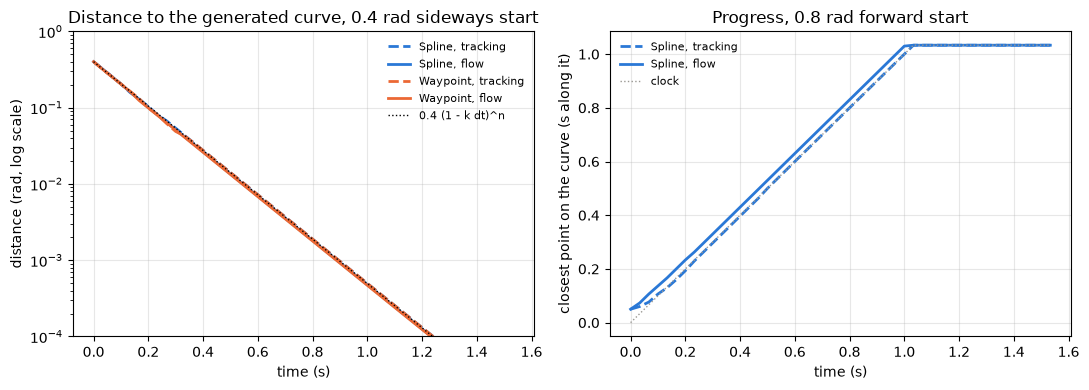

In [5]:
w = 0
t = np.arange(int(round((R.T_REF + 0.5) / R.DT)) + 1) * R.DT
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for name, (pos, vel) in refs.items():
    push = R.push_vectors(pos, vel, "perpendicular", 0.4, t_push=T_PUSH)
    for ctrl in ["tracking", "flow"]:
        _, dist, _ = R.simulate(pos[w:w + 1], ctrl, push[w:w + 1], t_push=T_PUSH, k=K_GAIN)
        axes[0].semilogy(t, dist[0] + 1e-6, color=COLOR[name], ls=STYLE[ctrl], lw=2, label=f"{name}, {ctrl}")
axes[0].semilogy(t, 0.4 * (1 - K_GAIN * R.DT) ** np.arange(len(t)), color="black", lw=1, ls=":",
                 label="0.4 (1 - k dt)^n")
axes[0].set(title="Distance to the generated curve, 0.4 rad sideways start", xlabel="time (s)",
            ylabel="distance (rad, log scale)", ylim=(1e-4, 1))
axes[0].legend(fontsize=8, frameon=False)

pos, vel = refs["Spline"]
push = R.push_vectors(pos, vel, "forward", 0.8, t_push=T_PUSH)
for ctrl in ["tracking", "flow"]:
    _, _, phase = R.simulate(pos[w:w + 1], ctrl, push[w:w + 1], t_push=T_PUSH, k=K_GAIN)
    axes[1].plot(t, phase[0], color=COLOR["Spline"], ls=STYLE[ctrl], lw=2, label=f"Spline, {ctrl}")
axes[1].plot(t, np.minimum(t, R.T_REF), color="#9a9893", lw=1, ls=":", label="clock")
axes[1].set(title="Progress, 0.8 rad forward start", xlabel="time (s)",
            ylabel="closest point on the curve (s along it)")
axes[1].legend(fontsize=8, frameon=False)
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(os.path.join(FIG, "recovery_initial_example.png"), dpi=150)
plt.show()

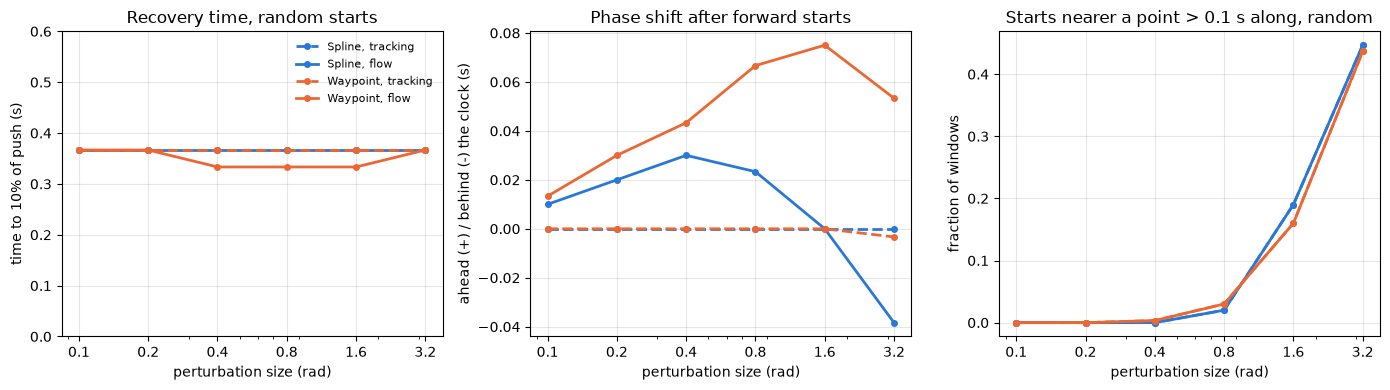

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for rep in refs:
    for ctrl in ["tracking", "flow"]:
        kw = dict(color=COLOR[rep], ls=STYLE[ctrl], lw=2, marker="o", ms=4, label=f"{rep}, {ctrl}")
        axes[0].plot(MAGS, [get("random", m, rep, ctrl, "recovery_time_s") for m in MAGS], **kw)
        axes[1].plot(MAGS, [get("forward", m, rep, ctrl, "phase_shift_s") for m in MAGS], **kw)
        axes[2].plot(MAGS, [get("random", m, rep, ctrl, "big_jump_frac") for m in MAGS], **kw)
axes[0].set(title="Recovery time, random starts", ylabel="time to 10% of push (s)", ylim=(0, 0.6))
axes[1].set(title="Phase shift after forward starts", ylabel="ahead (+) / behind (-) the clock (s)")
axes[2].set(title="Starts nearer a point > 0.1 s along, random", ylabel="fraction of windows")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xticks(MAGS, [str(m) for m in MAGS])
    ax.set_xlabel("perturbation size (rad)")
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(os.path.join(FIG, "recovery_initial_sweep.png"), dpi=150)
plt.show()